# 澳门街景特征提取试验：12 张宽幅图片

按 [特征定义表](../outputs/street_view_feature_plan_v1/特征定义表.md) 试运行。SegFormer-B2（Cityscapes）计算可见植被、建筑、天空比例；YOLO11s（COCO）计算机动车和人物实例。12 张图片含 11 个不同 SHA-256，精确重复图只推理一次。结果保存在 `outputs/street_view_feature_pilot_v1/`。

本 Notebook 的占比和目标数是**模型预测**。人工检查为定性检查，并非像素级或框级真值精度评估；具体道路点位尚未独立证实。

In [1]:
from pathlib import Path
import json, time, hashlib, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from PIL import Image, ImageDraw, ImageFont
import torch
import torch.nn.functional as F
from torchvision.ops import nms
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation
from ultralytics import YOLO
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'outputs/structured_data_v1/tables/images.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('请从毕业设计项目或 notebooks 目录运行')
OUT = ROOT / 'outputs/street_view_feature_pilot_v1'
PREVIEWS = OUT / 'previews'
MASKS = OUT / 'masks'
PREVIEWS.mkdir(parents=True, exist_ok=True)
MASKS.mkdir(parents=True, exist_ok=True)
WEIGHTS = OUT / 'weights/yolo11s.pt'
assert WEIGHTS.exists(), f'缺少权重：{WEIGHTS}'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(20261022)
np.random.seed(20261022)
plt.rcParams.update({'font.family':'Microsoft YaHei', 'axes.unicode_minus':False, 'figure.dpi':110})
print('Python:', sys.executable)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
print('Output:', OUT)

Python: C:\Users\25142\anaconda3\python.exe
Device: cuda NVIDIA GeForce RTX 4060 Laptop GPU
Output: E:\毕业设计\outputs\street_view_feature_pilot_v1


## 1. 样本与固定参数

覆盖三种道路等级和隧道、立交、城市密集街道、植被道路、施工画面；`2057/2567` 是字节完全相同的图片。下沿 8% 作为车头遮挡区，宽度 1024 像素、步长 768 像素的 5 个切片覆盖整图。参数是试验参数，需以人工标注样本检验。

In [2]:
SAMPLE_OBJECTIDS = [5241, 808, 3813, 1750, 3410, 2057, 2567, 4372, 4768, 6654, 1888, 4929]
PARAMS = {
    'sample_objectids': SAMPLE_OBJECTIDS,
    'bottom_exclusion_fraction': 0.08,
    'tile_width_px': 1024,
    'tile_step_px': 768,
    'seg_input_height_px': 768,
    'seg_input_width_px': 1024,
    'det_imgsz': 1024,
    'det_conf': 0.25,
    'det_iou_within_tile': 0.50,
    'det_iou_cross_tile': 0.50,
    'pedestrian_min_semantic_pixels': 100,
    'pedestrian_person_ratio': 0.70,
    'rider_max_person_ratio': 0.30,
    'model_seg': 'nvidia/segformer-b2-finetuned-cityscapes-1024-1024',
    'model_det': 'yolo11s.pt',
}
images = pd.read_csv(ROOT / 'outputs/structured_data_v1/tables/images.csv', encoding='utf-8-sig')
links = pd.read_csv(ROOT / 'outputs/image_road_linkage_v1/image_road_association.csv', encoding='utf-8-sig')
cols = ['image_id', 'road_id', 'fclass', 'road_name', 'visual_review_status']
sample = images.merge(links[cols], on='image_id', validate='one_to_one').set_index('source_objectid').loc[SAMPLE_OBJECTIDS].reset_index()
assert len(sample) == 12 and sample['sha256'].nunique() == 11
display(sample[['image_id','road_id','fclass','road_name','duplicate_of_image_id','visual_review_status']])
print('Images:', len(sample), 'unique SHA-256:', sample.sha256.nunique())

,image_id,road_id,fclass,road_name,duplicate_of_image_id,visual_review_status
0,MC-I005241,MC-R08044,primary,路氹連貫公路 Estrada do Istmo,NaN,location_unverified
1,MC-I000808,MC-R00291,primary,友誼大馬路 Avenida da Amizade,NaN,location_unverified
2,MC-I003813,MC-R05348,primary,奧林匹克游泳館圓形地行車天橋 Viaduto da Rotunda da Piscina O...,NaN,priority_manual_review
3,MC-I001750,MC-R01176,secondary,大學大馬路 Avenida da Universidade,NaN,priority_manual_review
4,MC-I003410,MC-R04520,secondary,竹灣馬路 Estrada de Cheoc Van,NaN,location_unverified
5,MC-I002057,MC-R01281,secondary,石排灣馬路 Estrada de Seac Pai Van,NaN,not_sampled
6,MC-I002567,MC-R02301,secondary,石排灣馬路 Estrada de Seac Pai Van,MC-I002057,location_unverified
7,MC-I004372,MC-R06358,tertiary,鄉村馬路 Estrada da Aldeia,NaN,location_unverified
8,MC-I004768,MC-R07152,tertiary,渡船街 Rua da Barca,NaN,location_unverified
9,MC-I006654,MC-R12437,tertiary,蝴蝶谷大馬路 Avenida de Vale das Borboletas,NaN,priority_manual_review


Images: 12 unique SHA-256: 11


## 2. 模型加载及预热

首次运行可下载 SegFormer 权重；YOLO 权重已保存于项目的 `weights/`。记录权重哈希和加载耗时。预热不纳入每图推理时间。

In [3]:
t_load = time.perf_counter()
seg_processor = AutoImageProcessor.from_pretrained(PARAMS['model_seg'])
seg_model = SegformerForSemanticSegmentation.from_pretrained(PARAMS['model_seg']).to(DEVICE).eval()
det_model = YOLO(str(WEIGHTS))
label_to_id = {v:k for k,v in seg_model.config.id2label.items()}
assert all(k in label_to_id for k in ['vegetation','building','sky','person','rider'])
load_seconds = time.perf_counter() - t_load
weight_sha = hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()
first_path = ROOT / 'outputs/structured_data_v1' / sample.iloc[0].relative_path
with Image.open(first_path) as im:
    first = np.array(im.convert('RGB').crop((0,0,1024,768)))
with torch.inference_mode():
    x = seg_processor(images=Image.fromarray(first), return_tensors='pt', size={'height':768,'width':1024})
    _ = seg_model(**{k:v.to(DEVICE) for k,v in x.items()}).logits
_ = det_model.predict(first, device=0 if DEVICE=='cuda' else 'cpu', imgsz=1024, conf=0.25, verbose=False)
if DEVICE == 'cuda': torch.cuda.synchronize()
print('Models loaded and warmed in', round(load_seconds,2), 's')
print('SegFormer labels:', seg_model.config.id2label)
print('YOLO weight SHA-256:', weight_sha)

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Models loaded and warmed in 6.05 s
SegFormer labels: {0: 'road', 1: 'sidewalk', 2: 'building', 3: 'wall', 4: 'fence', 5: 'pole', 6: 'traffic light', 7: 'traffic sign', 8: 'vegetation', 9: 'terrain', 10: 'sky', 11: 'person', 12: 'rider', 13: 'car', 14: 'truck', 15: 'bus', 16: 'train', 17: 'motorcycle', 18: 'bicycle'}
YOLO weight SHA-256: 85a76fe86dd8afe384648546b56a7a78580c7cb7b404fc595f97969322d502d5


## 3. 切片、语义图与检测框

语义图在切片重叠区域按中线只取一侧；检测框映射到原图后再做一次同类 NMS。原图下沿车头遮挡区不参与分割或检测。

In [4]:
CLASS_NAMES = {0:'person',2:'car',3:'motorcycle',5:'bus',7:'truck'}
MOTOR_IDS = {2,3,5,7}

def sync():
    if DEVICE == 'cuda': torch.cuda.synchronize()

def tile_starts(width):
    starts = list(range(0, max(1,width-PARAMS['tile_width_px']+1), PARAMS['tile_step_px']))
    last = width-PARAMS['tile_width_px']
    if starts[-1] != last: starts.append(last)
    return sorted(set(starts))

def one_image(row):
    path = ROOT / 'outputs/structured_data_v1' / row.relative_path
    t0 = time.perf_counter()
    with Image.open(path) as im:
        rgb = np.asarray(im.convert('RGB'))
    h,w = rgb.shape[:2]
    valid_h = round(h*(1-PARAMS['bottom_exclusion_fraction']))
    rgb = rgb[:valid_h]
    starts = tile_starts(w)
    mask = np.empty((valid_h,w), dtype=np.uint8)
    read_sec = time.perf_counter()-t0
    seg_sec = 0.0
    det_sec = 0.0
    all_boxes = []
    for i,x0 in enumerate(starts):
        x1 = x0 + PARAMS['tile_width_px']
        tile = rgb[:,x0:x1]
        ts = time.perf_counter()
        inputs = seg_processor(images=Image.fromarray(tile), return_tensors='pt', size={'height':PARAMS['seg_input_height_px'],'width':PARAMS['seg_input_width_px']})
        with torch.inference_mode():
            logits = seg_model(**{k:v.to(DEVICE) for k,v in inputs.items()}).logits
            up = F.interpolate(logits, size=tile.shape[:2], mode='bilinear', align_corners=False)
            tile_mask = up.argmax(1)[0].to('cpu',dtype=torch.uint8).numpy()
        sync()
        seg_sec += time.perf_counter()-ts
        left = 0 if i==0 else (starts[i-1]+PARAMS['tile_width_px']+x0)//2
        right = w if i==len(starts)-1 else (x1+starts[i+1])//2
        mask[:,left:right] = tile_mask[:,left-x0:right-x0]
        del inputs,logits,up,tile_mask

        td = time.perf_counter()
        pred = det_model.predict(tile, device=0 if DEVICE=='cuda' else 'cpu', imgsz=PARAMS['det_imgsz'], conf=PARAMS['det_conf'], iou=PARAMS['det_iou_within_tile'], classes=list(CLASS_NAMES), verbose=False)[0]
        sync()
        det_sec += time.perf_counter()-td
        boxes = pred.boxes
        for xyxy,cls,conf in zip(boxes.xyxy.cpu().numpy(), boxes.cls.cpu().numpy(), boxes.conf.cpu().numpy()):
            xa,ya,xb,yb = xyxy.tolist()
            all_boxes.append({'x1':xa+x0,'y1':ya,'x2':xb+x0,'y2':yb,'class_id':int(cls),'confidence':float(conf),'tile_x':x0})
    kept=[]
    for cls in CLASS_NAMES:
        group=[b for b in all_boxes if b['class_id']==cls]
        if not group: continue
        bt=torch.tensor([[b[k] for k in ('x1','y1','x2','y2')] for b in group],dtype=torch.float32)
        sc=torch.tensor([b['confidence'] for b in group])
        for j in nms(bt,sc,PARAMS['det_iou_cross_tile']).tolist():
            b=group[j]
            xa,ya,xb,yb=map(int,[max(0,b['x1']),max(0,b['y1']),min(w,b['x2']),min(valid_h,b['y2'])])
            if xb<=xa or yb<=ya: continue
            if cls==0:
                sub=mask[ya:yb,xa:xb]
                p=int(np.sum(sub==label_to_id['person']))
                r=int(np.sum(sub==label_to_id['rider']))
                ratio=p/(p+r) if p+r else np.nan
                b['person_semantic_px']=p
                b['rider_semantic_px']=r
                b['person_semantic_ratio']=ratio
                b['pedestrian_rule']='uncertain' if p+r<PARAMS['pedestrian_min_semantic_pixels'] else ('pedestrian' if ratio>=PARAMS['pedestrian_person_ratio'] else ('rider' if ratio<=PARAMS['rider_max_person_ratio'] else 'uncertain'))
            else:
                b['person_semantic_px']=0; b['rider_semantic_px']=0
                b['person_semantic_ratio']=np.nan; b['pedestrian_rule']='not_person'
            kept.append(b)
    counts={name:sum(b['class_id']==cid for b in kept) for cid,name in CLASS_NAMES.items()}
    features={
        'image_id':row.image_id,'sample_id':row.sample_id,'road_id':row.road_id,
        'fclass':row.fclass,'road_name':row.road_name,'source_sha256':row.sha256,
        'association_review_status':row.visual_review_status,
        'width_px':w,'height_px':h,'valid_height_px':valid_h,'valid_pixel_count':w*valid_h,
        'tile_count':len(starts),
        'vegetation_share':float(np.mean(mask==label_to_id['vegetation'])),
        'building_share':float(np.mean(mask==label_to_id['building'])),
        'sky_share':float(np.mean(mask==label_to_id['sky'])),
        'motor_vehicle_count':sum(counts[CLASS_NAMES[k]] for k in MOTOR_IDS),
        'person_count':counts['person'],
        'pedestrian_count_est':sum(b['pedestrian_rule']=='pedestrian' for b in kept),
        'pedestrian_uncertain_count':sum(b['pedestrian_rule']=='uncertain' for b in kept),
        'rider_count_est':sum(b['pedestrian_rule']=='rider' for b in kept),
        'read_sec':read_sec,'segmentation_sec':seg_sec,'detection_sec':det_sec,
        'inference_sec':seg_sec+det_sec,'cache_hit':False,'quality_status':'pending_manual_review',
    }
    for name,n in counts.items(): features[name+'_count']=n
    Image.fromarray(mask).save(MASKS/(row.image_id+'.png'))
    colors={label_to_id['vegetation']:(46,170,75),label_to_id['building']:(240,128,87),label_to_id['sky']:(64,162,230)}
    vis=rgb.copy()
    for cid,color in colors.items():
        loc=(mask==cid)
        vis[loc]=(vis[loc].astype(np.uint16)*55//100 + np.array(color,dtype=np.uint16)*45//100).astype(np.uint8)
    preview=Image.fromarray(vis)
    draw=ImageDraw.Draw(preview)
    for b in kept:
        color='#e8218a' if b['class_id']==0 else '#f5d427'
        draw.rectangle((b['x1'],b['y1'],b['x2'],b['y2']),outline=color,width=7)
        draw.text((b['x1'],max(0,b['y1']-24)),f"{CLASS_NAMES[b['class_id']]} {b['confidence']:.2f}",fill=color,stroke_width=2,stroke_fill='black')
    preview.thumbnail((1600,600))
    preview.save(PREVIEWS/(row.image_id+'.jpg'),quality=88)
    for b in kept:
        b['image_id']=row.image_id
    return features,kept


## 4. 批量试运行与结果保存

In [5]:
features=[]; detections=[]; by_sha={}
t_run=time.perf_counter()
for row in sample.itertuples(index=False):
    if row.sha256 in by_sha:
        original=by_sha[row.sha256]
        copy=original.copy()
        copy.update({'image_id':row.image_id,'sample_id':row.sample_id,'road_id':row.road_id,'fclass':row.fclass,'road_name':row.road_name,'association_review_status':row.visual_review_status,'read_sec':0.0,'segmentation_sec':0.0,'detection_sec':0.0,'inference_sec':0.0,'cache_hit':True})
        features.append(copy)
        source_id=original['image_id']
        (PREVIEWS/(row.image_id+'.jpg')).write_bytes((PREVIEWS/(source_id+'.jpg')).read_bytes())
        (MASKS/(row.image_id+'.png')).write_bytes((MASKS/(source_id+'.png')).read_bytes())
        for b in [x for x in detections if x['image_id']==source_id]:
            bc=b.copy(); bc['image_id']=row.image_id; detections.append(bc)
    else:
        f,boxes=one_image(row)
        features.append(f); detections.extend(boxes); by_sha[row.sha256]=f
    print(row.image_id, 'cache' if features[-1]['cache_hit'] else f"seg={features[-1]['segmentation_sec']:.2f}s det={features[-1]['detection_sec']:.2f}s",flush=True)
sync()
run_wall_sec=time.perf_counter()-t_run
feature_df=pd.DataFrame(features)
det_df=pd.DataFrame(detections)
feature_df.to_csv(OUT/'image_features_pilot.csv',index=False,encoding='utf-8-sig')
det_df.to_csv(OUT/'detections_pilot.csv',index=False,encoding='utf-8-sig')
parameters={**PARAMS,'python':sys.version.split()[0],'python_executable':sys.executable,'device':DEVICE,'gpu':torch.cuda.get_device_name(0) if DEVICE=='cuda' else None,'versions':{p:importlib.metadata.version(p) for p in ['torch','transformers','ultralytics','pillow','numpy','pandas']},'seg_model_commit':getattr(seg_model.config,'_commit_hash',None),'yolo_weight_sha256':weight_sha,'model_load_sec':load_seconds,'run_wall_sec':run_wall_sec,'n_images':len(feature_df),'n_unique_sha256':int(feature_df.source_sha256.nunique())}
(OUT/'parameters.json').write_text(json.dumps(parameters,ensure_ascii=False,indent=2),encoding='utf-8')
display(feature_df[['image_id','fclass','vegetation_share','building_share','sky_share','motor_vehicle_count','person_count','pedestrian_count_est','pedestrian_uncertain_count','inference_sec','cache_hit']].round(3))
print('Run wall seconds:',round(run_wall_sec,2))

MC-I005241 seg=0.69s det=0.13s


MC-I000808 seg=0.69s det=0.09s


MC-I003813 seg=0.68s det=0.08s


MC-I001750 seg=0.68s det=0.07s


MC-I003410 seg=0.69s det=0.08s


MC-I002057 seg=0.68s det=0.07s


... (4 outputs left out)

MC-I001888 seg=0.69s det=0.07s


MC-I004929 seg=0.70s det=0.08s


,image_id,fclass,vegetation_share,building_share,sky_share,motor_vehicle_count,person_count,pedestrian_count_est,pedestrian_uncertain_count,inference_sec,cache_hit
0,MC-I005241,primary,0.111,0.015,0.593,5,0,0,0,0.821,False
1,MC-I000808,primary,0.045,0.006,0.670,11,2,0,1,0.778,False
2,MC-I003813,primary,0.082,0.158,0.444,17,2,0,2,0.761,False
3,MC-I001750,secondary,0.110,0.079,0.000,1,0,0,0,0.757,False
4,MC-I003410,secondary,0.499,0.000,0.198,7,0,0,0,0.769,False
5,MC-I002057,secondary,0.102,0.202,0.428,2,0,0,0,0.757,False
6,MC-I002567,secondary,0.102,0.202,0.428,2,0,0,0,0.000,True
7,MC-I004372,tertiary,0.342,0.123,0.333,0,0,0,0,0.758,False
8,MC-I004768,tertiary,0.004,0.607,0.213,7,30,27,2,0.763,False
9,MC-I006654,tertiary,0.068,0.029,0.622,16,1,0,1,0.760,False


Run wall seconds: 13.75


## 5. 特征与耗时概览

同一张图像中的语义占比并不要求加和为 1，因为道路、人车、墙体等其余类别仍占画面；占比也不能解释为实际空间覆盖面积。下图给出试验样本的模型结果，质量结论需结合叠加图和人工复核。

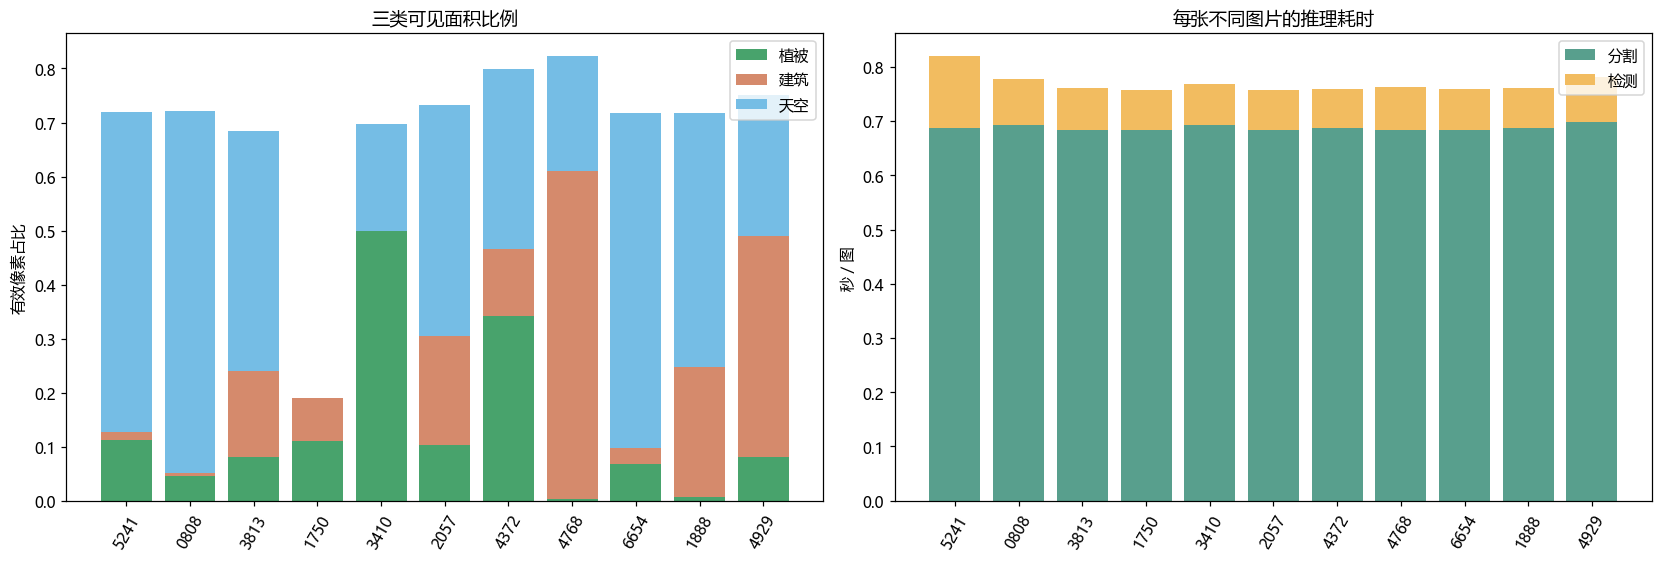

独立图片推理耗时中位数： 0.76 秒；平均数： 0.77 秒
检测目标总数： 133 （含复制的重复图记录）


In [6]:
unique=feature_df.drop_duplicates('source_sha256').copy()
fig,axs=plt.subplots(1,2,figsize=(15,5),layout='constrained')
ordr=np.arange(len(unique))
axs[0].bar(ordr,unique.vegetation_share,label='植被',color='#48a36c')
axs[0].bar(ordr,unique.building_share,bottom=unique.vegetation_share,label='建筑',color='#d58a6c')
axs[0].bar(ordr,unique.sky_share,bottom=unique.vegetation_share+unique.building_share,label='天空',color='#75bde5')
axs[0].set_xticks(ordr,unique.image_id.str[-4:],rotation=60)
axs[0].set_ylabel('有效像素占比'); axs[0].set_title('三类可见面积比例'); axs[0].legend()
axs[1].bar(ordr,unique.segmentation_sec,label='分割',color='#589f8d')
axs[1].bar(ordr,unique.detection_sec,bottom=unique.segmentation_sec,label='检测',color='#f2bc60')
axs[1].set_xticks(ordr,unique.image_id.str[-4:],rotation=60)
axs[1].set_ylabel('秒／图'); axs[1].set_title('每张不同图片的推理耗时'); axs[1].legend()
fig.savefig(OUT/'features_and_runtime.png',dpi=170,bbox_inches='tight')
plt.show()
print('独立图片推理耗时中位数：',round(unique.inference_sec.median(),2),'秒；平均数：',round(unique.inference_sec.mean(),2),'秒')
print('检测目标总数：',len(det_df),'（含复制的重复图记录）')

## 6. 预测叠加图索引

绿色＝植被、橘色＝建筑、蓝色＝天空；黄框＝机动车、粉框＝人物。叠加图与分割掩膜分别保存在 `previews/`、`masks/`。人工检查结论和问题清单写入试验报告。

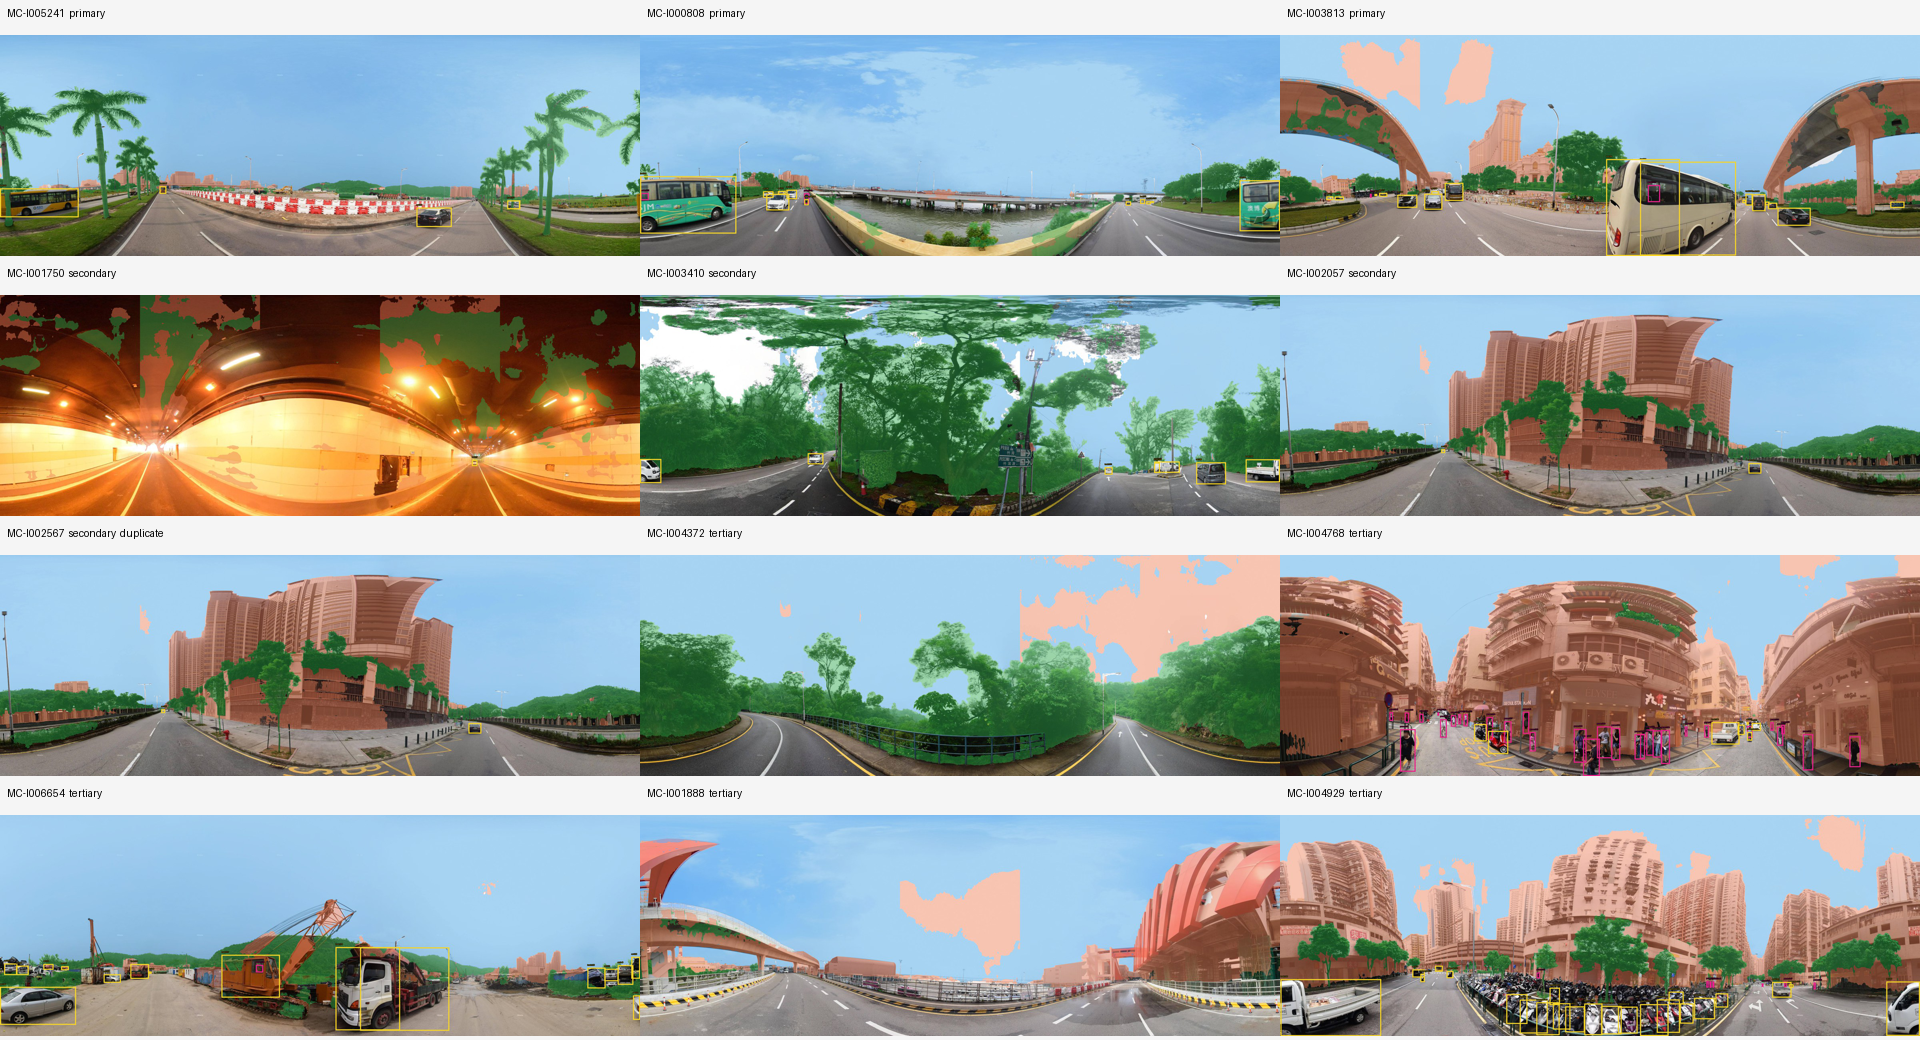

叠加图： E:\毕业设计\outputs\street_view_feature_pilot_v1\contact_sheet.jpg


In [7]:
cols=3; cell_w=640; title_h=35; image_h=225
rows=(len(sample)+cols-1)//cols
sheet=Image.new('RGB',(cols*cell_w,rows*(title_h+image_h)),(245,245,245))
draw=ImageDraw.Draw(sheet)
for i,row in enumerate(sample.itertuples(index=False)):
    img=Image.open(PREVIEWS/(row.image_id+'.jpg')).convert('RGB')
    img.thumbnail((cell_w,image_h))
    x=(i%cols)*cell_w; y=(i//cols)*(title_h+image_h)
    draw.text((x+7,y+7),f'{row.image_id}  {row.fclass}'+('  duplicate' if row.sha256==sample.iloc[5].sha256 and i==6 else ''),fill=(0,0,0))
    sheet.paste(img,(x,y+title_h))
sheet.save(OUT/'contact_sheet.jpg',quality=92)
display(sheet)
print('叠加图：',OUT/'contact_sheet.jpg')

## 7. 人工定性复核

逐张查看预测叠加图，记录肉眼可见的问题。`未见明显异常` 仅指这次目视检查没有发现大块错分或显著重框，**不是定量准确率**。精确重复图片复用同一复核结论。

In [8]:
MANUAL_REVIEW = {
    'MC-I005241':('未见明显异常','开阔道路的天空、树木和大车位置大体符合画面。'),
    'MC-I000808':('局部异常','海堤及水边局部被标为植被；人物框需核对是否为骑行者或车内人员。'),
    'MC-I003813':('明显异常','高架结构及部分天空错分；同一大客车出现重叠检测框，车窗内人物被检出。'),
    'MC-I001750':('明显异常','隧道顶棚大面积误判为植被；天空为零符合隧道场景。'),
    'MC-I003410':('未见明显异常','大面积树冠与道路的分割位置整体合理。'),
    'MC-I002057':('未见明显异常','建筑和道路位置整体合理，细小树木边缘仍需像素标注核验。'),
    'MC-I002567':('未见明显异常','与 MC-I002057 的 SHA-256 完全一致，结果从缓存复用。'),
    'MC-I004372':('明显异常','林地上方天空被大面积误判为建筑，切片边界出现明显类别突变。'),
    'MC-I004768':('局部异常','密集街道的建筑和人物框大体可解释，但 30 个人物框尚未逐个核真。'),
    'MC-I006654':('明显异常','施工机械被判机动车，同一货车附近有重叠框，16 辆计数不可直接使用。'),
    'MC-I001888':('明显异常','高架及天空局部被分为建筑，建筑可见占比缺乏可信解释。'),
    'MC-I004929':('局部异常','大量停放摩托车被计入机动车；人物／骑行者区分多数待判，不能解释为车流量。'),
}
assert set(MANUAL_REVIEW)==set(feature_df.image_id)
feature_df['quality_status']=feature_df.image_id.map(lambda x:MANUAL_REVIEW[x][0])
feature_df['quality_note']=feature_df.image_id.map(lambda x:MANUAL_REVIEW[x][1])
feature_df.to_csv(OUT/'image_features_pilot.csv',index=False,encoding='utf-8-sig')
review_df=feature_df[['image_id','source_sha256','quality_status','quality_note','association_review_status']].copy()
review_df.to_csv(OUT/'manual_review.csv',index=False,encoding='utf-8-sig')
display(review_df[['image_id','quality_status','quality_note']])
print('不同画面的人工定性分类：')
display(review_df.drop_duplicates('source_sha256').quality_status.value_counts())

,image_id,quality_status,quality_note
0,MC-I005241,未见明显异常,开阔道路的天空、树木和大车位置大体符合画面。
1,MC-I000808,局部异常,海堤及水边局部被标为植被；人物框需核对是否为骑行者或车内人员。
2,MC-I003813,明显异常,高架结构及部分天空错分；同一大客车出现重叠检测框，车窗内人物被检出。
3,MC-I001750,明显异常,隧道顶棚大面积误判为植被；天空为零符合隧道场景。
4,MC-I003410,未见明显异常,大面积树冠与道路的分割位置整体合理。
5,MC-I002057,未见明显异常,建筑和道路位置整体合理，细小树木边缘仍需像素标注核验。
6,MC-I002567,未见明显异常,与 MC-I002057 的 SHA-256 完全一致，结果从缓存复用。
7,MC-I004372,明显异常,林地上方天空被大面积误判为建筑，切片边界出现明显类别突变。
8,MC-I004768,局部异常,密集街道的建筑和人物框大体可解释，但 30 个人物框尚未逐个核真。
9,MC-I006654,明显异常,施工机械被判机动车，同一货车附近有重叠框，16 辆计数不可直接使用。


不同画面的人工定性分类：


quality_status
明显异常      5
未见明显异常    3
局部异常      3
Name: count, dtype: int64